In [ ]:
# utils.plot_new wasn't published, so use utils.plot instead
import torch
import torch.nn as nn
import torch.optim as optim
from models.codec import DenseED
from models.darcy import conv_constitutive_constraint as constitutive_constraint
from models.darcy import conv_continuity_constraint as continuity_constraint
from utils.image_gradient import SobelFilter
from utils.load import load_data
from utils.misc import mkdirs, to_numpy
from utils.plot import plot_prediction_det, save_stats

from utils.practices import OneCycleScheduler, adjust_learning_rate, find_lr
import time
import argparse
import random
from pprint import pprint
import json
import sys
import numpy as np
import matplotlib.pyplot as plt
plt.switch_backend('agg')

# replacements for files the authors didn't publish, training loop needs two PDE loss but repo only returns one, therefore returns both,  plot_prediction_det2 wasnt publisheed
def constitutive_constraint(input, output, sobel_filter):
    """sigma = -K * grad(u), returned as (horizontal, vertical) residuals.
    Checked against the FVM test data: both relations hold with ~0 error."""
    grad_h = sobel_filter.grad_h(output[:, [0]])
    grad_v = sobel_filter.grad_v(output[:, [0]])
    loss_h = ((output[:, [1]] + input * grad_h) ** 2).mean()
    loss_v = ((output[:, [2]] + input * grad_v) ** 2).mean()
    return loss_h, loss_v


def plot_prediction_det2(save_dir, target, prediction, epoch, index, plot_fn='contourf'):
    """Plots (u, |sigma|) into a subfolder so it doesn't overwrite plot_prediction_det's files."""
    sub_dir = save_dir + '/flux_magnitude'
    mkdirs(sub_dir)
    plot_prediction_det(sub_dir, target, prediction, epoch, index, plot_fn=plot_fn,
                        col_labels=['Pressure', 'Flux Magnitude'])


In [ ]:

class Parser(argparse.ArgumentParser):
    def __init__(self): 
        super(Parser, self).__init__(description='Learning surrogate with Hard Constraints')
        self.add_argument('--exp-name', type=str, default='FVM_lrstep095_hard_constraint/mixed_residual', help='experiment name')
        self.add_argument('--exp-dir', type=str, default="./experiments", help='directory to save experiments')      
        # codec
        self.add_argument('--blocks', type=list, default=[6, 8, 6], help='list of number of layers in each dense block')
        self.add_argument('--growth-rate', type=int, default=16, help='number of output feature maps of each conv layer')
        self.add_argument('--init-features', type=int, default=48, help='number of initial features after the first conv layer')      
        self.add_argument('--drop-rate', type=float, default=0., help='dropout rate')
        self.add_argument('--upsample', type=str, default='nearest', choices=['nearest', 'bilinear'])
        # data 
        self.add_argument('--data-dir', type=str, default="./datasets", help='directory to dataset')
        self.add_argument('--data', type=str, default='aniso', choices=['aniso', 'volume20','volume30', 'volume40','volume50', 'volume60','mixvolume'])
        self.add_argument('--ntrain', type=int, default=16384, help="number of training data")
        self.add_argument('--ntest', type=int, default=512, help="number of validation data")
        self.add_argument('--imsize', type=int, default=128)
        # training
        self.add_argument('--run', type=int, default=1, help='run instance')
        self.add_argument('--epochs', type=int, default=600, help='number of epochs to train')
        self.add_argument('--lr', type=float, default=1e-3, help='learning rate')
        self.add_argument('--lr-div', type=float, default=2., help='lr div factor to get the initial lr')
        self.add_argument('--lr-pct', type=float, default=0.3, help='percentage to reach the maximun lr')
        self.add_argument('--weight-decay', type=float, default=0., help="weight decay")
        self.add_argument('--weight-bound', type=float, default=10, help="weight for boundary loss (Unused in Hard Constraints)")
        self.add_argument('--batch-size', type=int, default=32, help='input batch size for training')
        self.add_argument('--test-batch-size', type=int, default=512, help='input batch size for testing')
        self.add_argument('--seed', type=int, default=1, help='manual seed')
        self.add_argument('--cuda', type=int, default=1, choices=[0, 1, 2, 3], help='cuda index')
        # logging
        self.add_argument('--debug', action='store_true', default=False, help='debug or verbose')
        self.add_argument('--ckpt-epoch', type=int, default=None, help='which epoch of checkpoints to be loaded')
        self.add_argument('--ckpt-freq', type=int, default=100, help='how many epochs to wait before saving model')
        self.add_argument('--log-freq', type=int, default=1, help='how many epochs to wait before logging')
        self.add_argument('--plot-freq', type=int, default=50, help='how many epochs to wait before plotting test output')
        self.add_argument('--plot-fn', type=str, default='contourf', choices=['contourf', 'imshow'], help='plotting method')

    def parse(self):
        # set options here because parse_args() kept crashing in jupyter when i ran it 
        args = self.parse_args(args=['--ntrain', '512', '--epochs', '2'])
        hparams = f'{args.data}_ntrain{args.ntrain}_run{args.run}_bs{args.batch_size}_lr{args.lr}_epochs{args.epochs}'
        if args.debug:
            hparams = 'debug/' + hparams
        args.run_dir = args.exp_dir + '/' + args.exp_name + '/' + hparams
        args.ckpt_dir = args.run_dir + '/checkpoints'
        mkdirs(args.run_dir, args.ckpt_dir) 

        assert args.ntrain % args.batch_size == 0 and args.ntest % args.test_batch_size == 0 

        if args.seed is None:
            args.seed = random.randint(1, 10000) 
        print("Random Seed: ", args.seed)
        random.seed(args.seed)
        torch.manual_seed(args.seed)

        print('Arguments:')
        pprint(vars(args))
        with open(args.run_dir + "/args.txt", 'w') as args_file:
            json.dump(vars(args), args_file, indent=4) 

        return args




In [ ]:
# rewrote this wrapper. The old version multiplied ALL outputs by a mask that is 0 on ALL four edges, forcing u = 0 and both fluxes = 0 everywhere on the boundary. The data has u = 1 on the left edge and nonzero flux there, so the old wrapper could only learn the trivial solution u = 0.
class HardConstraintWrapper(nn.Module):
    """
    Wraps the neural network to apply hard boundary constraints that match the data:
      u = 1 at left (x=0), u = 0 at right (x=1)   -> u  = (1 - x) + 4x(1-x) * N_u
      sigma_2 = 0 at top/bottom (y=0, y=1)       -> s2 = 4y(1-y) * N_s2
      sigma_1 unconstrained                      -> s1 = N_s1
    """
    def __init__(self, base_model, imsize, device):
        super().__init__()
        self.base_model = base_model

        # 2D coordinate grid from 0 to 1 (x along columns, y along rows)
        x = torch.linspace(0, 1, steps=imsize, device=device)
        y = torch.linspace(0, 1, steps=imsize, device=device)
        grid_y, grid_x = torch.meshgrid(y, x, indexing='ij')

        # Reshape to (1, 1, imsize, imsize) to broadcast across batches
        self.register_buffer('u_bc',   (1.0 - grid_x).view(1, 1, imsize, imsize))
        self.register_buffer('mask_x', (4.0 * grid_x * (1 - grid_x)).view(1, 1, imsize, imsize))
        self.register_buffer('mask_y', (4.0 * grid_y * (1 - grid_y)).view(1, 1, imsize, imsize))

    def forward(self, input_tensor):
        # Raw prediction from DenseED
        raw = self.base_model(input_tensor)

        # Apply the hard-constraint ansatz per output channel
        u  = self.u_bc + self.mask_x * raw[:, [0]]
        s1 = raw[:, [1]]
        s2 = self.mask_y * raw[:, [2]]
        return torch.cat([u, s1, s2], dim=1)



In [ ]:
if __name__ == '__main__':

    args = Parser().parse()
    device = torch.device(f"cuda:{args.cuda}" if torch.cuda.is_available() else "cpu")

    args.train_dir = args.run_dir + '/training' 
    args.pred_dir = args.train_dir + '/predictions' 
    mkdirs(args.train_dir, args.pred_dir)

    # Initialize the base model
    base_model = DenseED(in_channels=1, out_channels=3, 
                    imsize=args.imsize,
                    blocks=args.blocks,
                    growth_rate=args.growth_rate, 
                    init_features=args.init_features,
                    drop_rate=args.drop_rate,
                    out_activation=None,
                    upsample=args.upsample)
    
    # removed exact_boundary_val=0.0 (the new wrapper sets the boundary values itself)
    model = HardConstraintWrapper(base_model, args.imsize, device)

    if args.debug:
        print(model.base_model)

    # if start from ckpt
    if args.ckpt_epoch is not None:
        ckpt_file = args.run_dir + f'/checkpoints/model_epoch{args.ckpt_epoch}.pth'
        # Load weights directly into the base DenseED model
        model.base_model.load_state_dict(torch.load(ckpt_file, map_location='cpu'))
        print(f'Loaded ckpt: {ckpt_file}')
        print(f'Resume training from epoch {args.ckpt_epoch + 1} to {args.epochs}')
    model = model.to(device)

    # load data
    if args.data == 'aniso':
        train_hdf5_file = args.data_dir + f'/{args.imsize}x{args.imsize}/FVM_aniso_ext128pixel_n19680_train.hdf5'
        test_hdf5_file = args.data_dir + f'/{args.imsize}x{args.imsize}/FVM_aniso_ext128pixel_n574_test.hdf5'
        ntrain_total, ntest_total = 19680, 512 
    elif args.data == 'volume20':
        train_hdf5_file = args.data_dir + f'/{args.imsize}x{args.imsize}/volume20_64pixel_n4100_train.hdf5'
        test_hdf5_file = args.data_dir + f'/{args.imsize}x{args.imsize}/volume20_64pixel_n512_test.hdf5'
        ntrain_total, ntest_total = 4100, 512 
    elif args.data == 'volume30':
        train_hdf5_file = args.data_dir + f'/{args.imsize}x{args.imsize}/volume30_64pixel_n4100_train.hdf5'
        test_hdf5_file = args.data_dir + f'/{args.imsize}x{args.imsize}/volume30_64pixel_n512_test.hdf5'
        ntrain_total, ntest_total = 4100, 512 
    elif args.data == 'volume40':
        train_hdf5_file = args.data_dir + f'/{args.imsize}x{args.imsize}/volume40_64pixel_n4100_train.hdf5'
        test_hdf5_file = args.data_dir + f'/{args.imsize}x{args.imsize}/volume40_64pixel_n512_test.hdf5'
        ntrain_total, ntest_total = 4100, 512 
    elif args.data == 'volume50':
        train_hdf5_file = args.data_dir + f'/{args.imsize}x{args.imsize}/volume50_64pixel_n4100_train.hdf5'
        test_hdf5_file = args.data_dir + f'/{args.imsize}x{args.imsize}/volume50_64pixel_n512_test.hdf5'
        ntrain_total, ntest_total = 4100, 512 
    elif args.data == 'volume60':
        train_hdf5_file = args.data_dir + f'/{args.imsize}x{args.imsize}/volume60_64pixel_n4100_train.hdf5'
        test_hdf5_file = args.data_dir + f'/{args.imsize}x{args.imsize}/volume60_64pixel_n512_test.hdf5'
        ntrain_total, ntest_total = 4100, 512 
    elif args.data == 'mixvolume':
        train_hdf5_file = args.data_dir + f'/{args.imsize}x{args.imsize}/mixvolume_64pixel_n9840_train.hdf5'
        test_hdf5_file = args.data_dir + f'/{args.imsize}x{args.imsize}/mixvolume_64pixel_n1148_test.hdf5'
        ntrain_total, ntest_total = 9840, 1148 

    assert args.ntrain <= ntrain_total, f"Only {args.ntrain_total} data available in dataset, needs {args.ntrain}"
    assert args.ntest <= ntest_total, f"Only {args.ntest_total} data available in dataset, needs {args.ntest}" 

    train_loader, _ = load_data(train_hdf5_file, args.ntrain, args.batch_size, only_input=True, return_stats=False)                       
    test_loader, test_stats = load_data(test_hdf5_file, args.ntest, args.test_batch_size, only_input=False, return_stats=True) 
    y_test_variation = test_stats['y_variation']            
    print(f'Test output variation per channel: {y_test_variation}')

    optimizer = optim.Adam(model.parameters(), lr=args.lr, weight_decay=args.weight_decay)        
    scheduler = OneCycleScheduler(lr_max=args.lr, div_factor=args.lr_div, pct_start=args.lr_pct)
    sobel_filter = SobelFilter(args.imsize, correct=True, device=device)

    n_out_pixels = test_loader.dataset[0][1].numel() 
    print(f'Number of out pixels per image: {n_out_pixels}') 

    logger = {}
    logger['loss_train'] = []
    logger['loss_test'] = []
    logger['r2_test'] = []
    logger['nrmse_test'] = []
    logger['nrmse_test_origin'] = []

    def test(epoch):
        model.eval()       
        loss_test = 0.
        relative_l2, err2 = [], []
        relative_l2_origin, err2_origin = [], []
        for batch_idx, (input, target) in enumerate(test_loader):
            input, target = input.to(device), target.to(device)   
            time_pre=time.time()
            output = model(input)          
            time_pre2=time.time()
            # subtraction was reversed (printed negative times)
            print(f'Finished predicting {args.test_batch_size} samples using: {(time_pre2 - time_pre):.6f} secs')
            
            loss_pde1, loss_pde2 = constitutive_constraint(input, output, sobel_filter)
            loss_pde3 = continuity_constraint(output, sobel_filter)
            

            loss = loss_pde1 + 10*loss_pde2 + loss_pde3
            loss_test += loss.item()

            # sum over H, W --> (B, C)
            err2_sum_origin = torch.sum((output - target) ** 2, [-1, -2])
            relative_l2_origin.append(torch.sqrt(err2_sum_origin / (target ** 2).sum([-1, -2])))
            err2_origin.append(err2_sum_origin)                                 

            output1=output[:,[0,1]]
            output1[:,[1]]=torch.sqrt(output[:,[1]]**2+output[:,[2]]**2)
            target1=target[:,[0,1]]
            target1[:,[1]]=torch.sqrt(target[:,[1]]**2+target[:,[2]]**2)
            err2_sum = torch.sum((output1 - target1) ** 2, [-1, -2])
            relative_l2.append(torch.sqrt(err2_sum / (target1 ** 2).sum([-1, -2])))
            err2.append(err2_sum)

            # plot predictions
            if (epoch % args.plot_freq == 0 or epoch == args.epochs) and batch_idx == len(test_loader) - 1:                                        
                n_samples = 512 if epoch == args.epochs else 2                          
                
                if (epoch == args.epochs):
                    for ii in range(args.test_batch_size):
                        print(f"writing test samples {ii}")
                        samples_input1=input.data.cpu()[ii].numpy()
                        samples_output1=output.data.cpu()[ii].numpy()
                        samples_target1=target.data.cpu()[ii].numpy()
                        np.savetxt(args.pred_dir+f"/input{ii}.txt", samples_input1[0])
                        np.savetxt(args.pred_dir+f"/output{ii}.txt", samples_output1[0])
                        np.savetxt(args.pred_dir+f"/target{ii}.txt", samples_target1[0])
                        np.savetxt(args.pred_dir+f"/target_fx{ii}.txt", samples_target1[1])
                        np.savetxt(args.pred_dir+f"/target_fy{ii}.txt", samples_target1[2])
                        np.savetxt(args.pred_dir+f"/output_fx{ii}.txt", samples_output1[1])
                        np.savetxt(args.pred_dir+f"/output_fy{ii}.txt", samples_output1[2])
                        del samples_input1, samples_output1, samples_target1

                idx = torch.randperm(input.size(0))[:n_samples]
                samples_output = output.data.cpu()[idx].numpy()
                samples_target = target.data.cpu()[idx].numpy()
                samples_output1 = output1.data.cpu()[idx].numpy()
                samples_target1 = target1.data.cpu()[idx].numpy()
                for i in range(n_samples):
                    print('epoch {}: plotting prediction {}'.format(epoch, i))
                    plot_prediction_det(args.pred_dir, samples_target[i], samples_output[i], epoch, i, plot_fn=args.plot_fn)          
                    plot_prediction_det2(args.pred_dir, samples_target1[i], samples_output1[i], epoch, i, plot_fn=args.plot_fn)         

        loss_test /= (batch_idx + 1)
        relative_l2 = to_numpy(torch.cat(relative_l2, 0).mean(0))
        relative_l2_origin = to_numpy(torch.cat(relative_l2_origin, 0).mean(0))
        r2_score = 1 - to_numpy(torch.cat(err2_origin, 0).sum(0)) / y_test_variation              
        print(f"Epoch: {epoch}, test r2-score:  {r2_score}")
        print(f"Epoch: {epoch}, test relative-l2:  {relative_l2}")
        print(f'Epoch {epoch}: test loss (PDE only): {loss_test:.6f}')            

        if epoch % args.log_freq == 0:
            logger['loss_test'].append(loss_test)
            logger['r2_test'].append(r2_score)
            logger['nrmse_test'].append(relative_l2)            
            logger['nrmse_test_origin'].append(relative_l2_origin)

    print('Start training...................................................')
    start_epoch = 1 if args.ckpt_epoch is None else args.ckpt_epoch + 1  
    tic = time.time()
    total_steps = args.epochs * len(train_loader)   
    print(f'total steps: {total_steps}')
    
    for epoch in range(start_epoch, args.epochs + 1):
        time_train=time.time()
        model.train()                          
        loss_train = 0.
        
        for batch_idx, (input, ) in enumerate(train_loader, start=1):            
            input = input.to(device)
            model.zero_grad()
            
            output = model(input)
            
            loss_pde1, loss_pde2 = constitutive_constraint(input, output, sobel_filter)
            loss_pde3 = continuity_constraint(output, sobel_filter)
            
            # Hard Constraint: Only optimize the interior physics
            loss_pde = loss_pde1 + 10*loss_pde2 + loss_pde3
            loss = loss_pde
            
            loss.backward()
            
            # lr scheduling
            step = (epoch - 1) * len(train_loader) + batch_idx
            pct = step / total_steps
            lr = scheduler.step(pct)
            # old code overwrote learning rate (krishna said to fix)
            adjust_learning_rate(optimizer, lr)
            optimizer.step()
            loss_train += loss.item()

        loss_train /= batch_idx
        time_train2=time.time()
        print(f'Epoch {epoch}, lr {lr:.6f}')
        print(f'Epoch {epoch}: training loss (PDE only): {loss_train:.6f}')
        # subtraction was reversed (printed negative times)
        print(f'Finished training epoch {epoch} using: {(time_train2 - time_train) / 60:.2f} mins')
        
        if epoch % args.log_freq == 0:
            logger['loss_train'].append(loss_train)                                            
        if epoch % args.ckpt_freq == 0:
            # Save the base model weights, avoiding the wrapper's buffer keys
            torch.save(model.base_model.state_dict(), args.ckpt_dir + "/model_epoch{}.pth".format(epoch)) 
        
        with torch.no_grad():
            time_test=time.time()
            test(epoch)
            time_test2=time.time()
            # subtraction was reversed (printed negative times)
            print(f'Finished test epoch {epoch} using: {(time_test2 - time_test) / 60:.2f} mins')     

    tic2 = time.time()
    print(f'Finished training {args.epochs} epochs with {args.ntrain} data using {(tic2 - tic) / 60:.2f} mins')                                 
    metrics = ['loss_train', 'loss_test', 'nrmse_test','nrmse_test_origin', 'r2_test']             
    save_stats(args.train_dir, logger, *metrics)                              
    args.training_time = tic2 - tic
    args.n_params, args.n_layers = model.base_model.model_size
    with open(args.run_dir + "/args.txt", 'w') as args_file:
        json.dump(vars(args), args_file, indent=4)

Random Seed:  1
Arguments:
{'batch_size': 32,
 'blocks': [6, 8, 6],
 'ckpt_dir': './experiments/FVM_lrstep095_hard_constraint/mixed_residual/aniso_ntrain512_run1_bs32_lr0.001_epochs2/checkpoints',
 'ckpt_epoch': None,
 'ckpt_freq': 100,
 'cuda': 1,
 'data': 'aniso',
 'data_dir': './datasets',
 'debug': False,
 'drop_rate': 0.0,
 'epochs': 2,
 'exp_dir': './experiments',
 'exp_name': 'FVM_lrstep095_hard_constraint/mixed_residual',
 'growth_rate': 16,
 'imsize': 128,
 'init_features': 48,
 'log_freq': 1,
 'lr': 0.001,
 'lr_div': 2.0,
 'lr_pct': 0.3,
 'ntest': 512,
 'ntrain': 512,
 'plot_fn': 'contourf',
 'plot_freq': 50,
 'run': 1,
 'run_dir': './experiments/FVM_lrstep095_hard_constraint/mixed_residual/aniso_ntrain512_run1_bs32_lr0.001_epochs2',
 'seed': 1,
 'test_batch_size': 512,
 'upsample': 'nearest',
 'weight_bound': 10,
 'weight_decay': 0.0}
# params 740091, # conv layers 28
x_data: (512, 1, 128, 128)
Loaded dataset: ./datasets/128x128/FVM_aniso_ext128pixel_n19680_train.hdf5
x_data

## ADDED: Soft vs. hard boundary-condition experiments

Each configuration is in its own cell and is trained with **3 seeds**. Every run uses the same data, model, optimizer and **one-cycle learning-rate schedule**.

| Cell | Method | Loss |
|---|---|---|
| Soft, w = 1 / 10 / 100 / 1000 | Original paper (soft BC) | PDE + w · (Dirichlet + Neumann) |
| Hard | `HardConstraintWrapper` | PDE only (BCs built into the output) |

Three metrics are reported **separately** for every run, all on the same FVM test set:
- **relL2**: relative L2 error vs the FVM solutions (u, σ₁, σ₂, and their mean)
- **bc_error**: MSE(u − 1, left) + MSE(u, right) + MSE(σ₂, top/bottom)
- **pde_interior**: mean squared PDE residual (constitutive + continuity) on interior pixels

Run the setup cell first, then any of the case cells, then the summary. Training settings are at the top of the setup cell.

In [ ]:

# added new steup for soft vs hard

import h5py
from torch.utils.data import DataLoader, TensorDataset
from models.darcy import conv_boundary_condition as boundary_condition   # boundary loss added

# ---- Settings shared by EVERY run (increase for final results) ----
NTRAIN = 512          # training inputs   (paper: 16384)
NTEST  = 512          # test FVM solutions, the same 512 for every run
EPOCHS = 10           # paper: 300-600 --> to computationally intensive. 
SEEDS  = [1, 2, 3]    # 3 seeds per configuration
TEST_BATCH = 64

exp_args = Parser().parse_args(args=[])   

exp_device = torch.device('cuda' if torch.cuda.is_available()
                          else 'mps' if torch.backends.mps.is_available() else 'cpu')
print('Device:', exp_device)

data_dir = exp_args.data_dir + f'/{exp_args.imsize}x{exp_args.imsize}'
with h5py.File(data_dir + '/FVM_aniso_ext128pixel_n19680_train.hdf5', 'r') as f:
    x_train = torch.FloatTensor(f['input'][:NTRAIN])
with h5py.File(data_dir + '/FVM_aniso_ext128pixel_n574_test.hdf5', 'r') as f:
    x_test = torch.FloatTensor(f['input'][:NTEST])
    y_test = torch.FloatTensor(f['output'][:NTEST])
test_loader_exp = DataLoader(TensorDataset(x_test, y_test), batch_size=TEST_BATCH, shuffle=False)
sobel_exp = SobelFilter(exp_args.imsize, correct=True, device=exp_device)
print(f'Train inputs: {tuple(x_train.shape)}, test: {tuple(x_test.shape)} -> {tuple(y_test.shape)}')


def build_model(mode):
    """mode = 'soft' -> plain DenseED (original paper), 'hard' -> DenseED inside HardConstraintWrapper."""
    base = DenseED(in_channels=1, out_channels=3,
                   imsize=exp_args.imsize,
                   blocks=exp_args.blocks,
                   growth_rate=exp_args.growth_rate,
                   init_features=exp_args.init_features,
                   drop_rate=exp_args.drop_rate,
                   out_activation=None,
                   upsample=exp_args.upsample)
    model = HardConstraintWrapper(base, exp_args.imsize, exp_device) if mode == 'hard' else base
    return model.to(exp_device)


def pde_loss(input, output):
    # Same PDE loss as the original training loop
    loss_pde1, loss_pde2 = constitutive_constraint(input, output, sobel_exp)
    loss_pde3 = continuity_constraint(output, sobel_exp)
    return loss_pde1 + 10 * loss_pde2 + loss_pde3


def train_one(mode, weight_bound, seed, verbose=True):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    model = build_model(mode)
    loader = DataLoader(TensorDataset(x_train), batch_size=exp_args.batch_size, shuffle=True,
                        drop_last=True, generator=torch.Generator().manual_seed(seed))
    optimizer = optim.Adam(model.parameters(), lr=exp_args.lr, weight_decay=exp_args.weight_decay)
    # use one-cycle learning rate scedule for every run
    scheduler = OneCycleScheduler(lr_max=exp_args.lr, div_factor=exp_args.lr_div, pct_start=exp_args.lr_pct)
    total_steps = EPOCHS * len(loader)

    for epoch in range(1, EPOCHS + 1):
        model.train()
        loss_train = 0.
        for batch_idx, (input, ) in enumerate(loader, start=1):
            input = input.to(exp_device)
            model.zero_grad()
            output = model(input)
            loss = pde_loss(input, output)
            if mode == 'soft':
                loss_dirichlet, loss_neumann = boundary_condition(output)
                loss = loss + weight_bound * (loss_dirichlet + loss_neumann)
            loss.backward()
            pct = ((epoch - 1) * len(loader) + batch_idx) / total_steps
            lr = adjust_learning_rate(optimizer, scheduler.step(pct))
            optimizer.step()
            loss_train += loss.item()
        if verbose:
            print(f'    epoch {epoch:3d}/{EPOCHS}  train loss {loss_train / batch_idx:.4e}  lr {lr:.2e}')
    return model


def interior_pde_residual(input, output, border=2):
    """Unweighted mean of (constitutive_h^2 + constitutive_v^2 + continuity^2), interior pixels only."""
    u, s1, s2 = output[:, [0]], output[:, [1]], output[:, [2]]
    r1 = s1 + input * sobel_exp.grad_h(u)
    r2 = s2 + input * sobel_exp.grad_v(u)
    r3 = sobel_exp.grad_h(s1) + sobel_exp.grad_v(s2)
    r = r1 ** 2 + r2 ** 2 + r3 ** 2
    return r[..., border:-border, border:-border].mean()


@torch.no_grad()
def evaluate(model):
    """Three separate metrics on the same FVM test set:
       relative L2 vs FVM (per channel), boundary error (same BC terms as the soft loss), interior PDE residual."""
    if model is not None:
        model.eval()
    rel, bc, pde, n = [], 0., 0., 0
    for input, target in test_loader_exp:
        input, target = input.to(exp_device), target.to(exp_device)
        output = target if model is None else model(input)       # model=None -> evaluate the FVM solution itself
        err2 = torch.sum((output - target) ** 2, [-1, -2])
        rel.append(torch.sqrt(err2 / torch.sum(target ** 2, [-1, -2])))
        loss_dirichlet, loss_neumann = boundary_condition(output)
        bc += (loss_dirichlet + loss_neumann).item() * input.size(0)
        pde += interior_pde_residual(input, output).item() * input.size(0)
        n += input.size(0)
    rel = torch.cat(rel, 0).mean(0).cpu().numpy()
    return {'relL2_u': rel[0], 'relL2_s1': rel[1], 'relL2_s2': rel[2],
            'relL2_mean': rel.mean(), 'bc_error': bc / n, 'pde_interior': pde / n}


METRICS = ['relL2_u', 'relL2_s1', 'relL2_s2', 'relL2_mean', 'bc_error', 'pde_interior']
results = {}

def print_row(name, rows):
    cells = []
    for k in METRICS:
        v = np.array([r[k] for r in rows])
        cells.append(f'{v.mean():.3e}' + (f' ± {v.std():.1e}' if len(v) > 1 else ' ' * 10))
    print(f'{name:<14}' + ''.join(f'{c:>22}' for c in cells))

def print_header():
    print(f'{"":<14}' + ''.join(f'{k:>22}' for k in METRICS))

def run_config(name, mode, weight_bound=None):
    rows = []
    for seed in SEEDS:
        print(f'[{name}] seed {seed}')
        t0 = time.time()
        model = train_one(mode, weight_bound, seed)
        m = evaluate(model)
        m['minutes'] = (time.time() - t0) / 60
        print('    ' + ', '.join(f'{k}={m[k]:.3e}' for k in METRICS) + f'  ({m["minutes"]:.1f} min)')
        rows.append(m)
    results[name] = rows
    print_header(); print_row(name, rows)
    return rows

# Reference the FVM solution itself 
reference = evaluate(None)
print('\nFVM reference (target evaluated against itself):')
print_header(); print_row('FVM truth', [reference])


Device: mps
Train inputs: (512, 1, 128, 128), test: (512, 1, 128, 128) -> (512, 3, 128, 128)

FVM reference (target evaluated against itself):
                             relL2_u              relL2_s1              relL2_s2            relL2_mean              bc_error          pde_interior
FVM truth        0.000e+00             0.000e+00             0.000e+00             0.000e+00             2.941e-03             2.820e+01          


In [ ]:
# Soft BC, weight_bound = 1  
run_config('soft_w1', 'soft', weight_bound=1)


[soft_w1] seed 1
# params 740091, # conv layers 28
    epoch   1/10  train loss 4.2913e+02  lr 6.67e-04
    epoch   2/10  train loss 7.2232e+00  lr 8.33e-04
    epoch   3/10  train loss 3.4860e+00  lr 1.00e-03
    epoch   4/10  train loss 2.4046e+00  lr 9.50e-04
    epoch   5/10  train loss 2.0026e+00  lr 8.12e-04
    epoch   6/10  train loss 1.8073e+00  lr 6.11e-04
    epoch   7/10  train loss 1.7069e+00  lr 3.89e-04
    epoch   8/10  train loss 1.6458e+00  lr 1.88e-04
    epoch   9/10  train loss 1.6220e+00  lr 4.96e-05
    epoch  10/10  train loss 1.6153e+00  lr 5.00e-08
    relL2_u=9.768e-01, relL2_s1=9.966e-01, relL2_s2=1.133e+00, relL2_mean=1.036e+00, bc_error=9.719e-01, pde_interior=7.824e-01  (3.5 min)
[soft_w1] seed 2
# params 740091, # conv layers 28
    epoch   1/10  train loss 6.9869e+02  lr 6.67e-04
    epoch   2/10  train loss 1.2894e+01  lr 8.33e-04
    epoch   3/10  train loss 4.9433e+00  lr 1.00e-03
    epoch   4/10  train loss 3.1507e+00  lr 9.50e-04
    epoch   5/10 

[{'relL2_u': np.float32(0.9768149),
  'relL2_s1': np.float32(0.99663556),
  'relL2_s2': np.float32(1.1330519),
  'relL2_mean': np.float32(1.0355008),
  'bc_error': 0.9719032570719719,
  'pde_interior': 0.7823568694293499,
  'minutes': 3.452807931105296},
 {'relL2_u': np.float32(0.9763831),
  'relL2_s1': np.float32(1.0356438),
  'relL2_s2': np.float32(1.0498439),
  'relL2_mean': np.float32(1.0206236),
  'bc_error': 0.9257019758224487,
  'pde_interior': 1.2358612418174744,
  'minutes': 3.9532764673233034},
 {'relL2_u': np.float32(1.0085692),
  'relL2_s1': np.float32(1.006927),
  'relL2_s2': np.float32(1.0535196),
  'relL2_mean': np.float32(1.0230054),
  'bc_error': 1.0248097330331802,
  'pde_interior': 1.5256052911281586,
  'minutes': 4.0946797132492065}]

In [ ]:
# Soft BC, weight_bound = 10  
run_config('soft_w10', 'soft', weight_bound=10)


[soft_w10] seed 1
# params 740091, # conv layers 28
    epoch   1/10  train loss 4.3940e+02  lr 6.67e-04
    epoch   2/10  train loss 1.5362e+01  lr 8.33e-04
    epoch   3/10  train loss 1.0987e+01  lr 1.00e-03
    epoch   4/10  train loss 9.2604e+00  lr 9.50e-04
    epoch   5/10  train loss 8.2389e+00  lr 8.12e-04
    epoch   6/10  train loss 7.6958e+00  lr 6.11e-04
    epoch   7/10  train loss 7.4029e+00  lr 3.89e-04
    epoch   8/10  train loss 7.2118e+00  lr 1.88e-04
    epoch   9/10  train loss 7.1349e+00  lr 4.96e-05
    epoch  10/10  train loss 7.1118e+00  lr 5.00e-08
    relL2_u=8.612e-01, relL2_s1=9.724e-01, relL2_s2=1.138e+00, relL2_mean=9.905e-01, bc_error=5.623e-01, pde_interior=1.429e+00  (4.4 min)
[soft_w10] seed 2
# params 740091, # conv layers 28
    epoch   1/10  train loss 7.0419e+02  lr 6.67e-04
    epoch   2/10  train loss 1.8577e+01  lr 8.33e-04
    epoch   3/10  train loss 1.0175e+01  lr 1.00e-03
    epoch   4/10  train loss 8.2862e+00  lr 9.50e-04
    epoch   5/1

[{'relL2_u': np.float32(0.8612468),
  'relL2_s1': np.float32(0.9723793),
  'relL2_s2': np.float32(1.1379557),
  'relL2_mean': np.float32(0.99052733),
  'bc_error': 0.5623287372291088,
  'pde_interior': 1.4288741052150726,
  'minutes': 4.356648234526316},
 {'relL2_u': np.float32(0.8681463),
  'relL2_s1': np.float32(1.0167491),
  'relL2_s2': np.float32(1.0394182),
  'relL2_mean': np.float32(0.9747712),
  'bc_error': 0.49445025622844696,
  'pde_interior': 1.6657053232192993,
  'minutes': 4.384006635348002},
 {'relL2_u': np.float32(0.9429079),
  'relL2_s1': np.float32(0.99768347),
  'relL2_s2': np.float32(1.0522202),
  'relL2_mean': np.float32(0.9976039),
  'bc_error': 0.8637765496969223,
  'pde_interior': 1.7151708751916885,
  'minutes': 4.284762668609619}]

In [ ]:
# Soft BC, weight_bound = 100  
run_config('soft_w100', 'soft', weight_bound=100)


[soft_w100] seed 1
# params 740091, # conv layers 28


    epoch   1/10  train loss 4.7200e+02  lr 6.67e-04
    epoch   2/10  train loss 2.5924e+01  lr 8.33e-04
    epoch   3/10  train loss 1.8683e+01  lr 1.00e-03
    epoch   4/10  train loss 1.5833e+01  lr 9.50e-04
    epoch   5/10  train loss 1.4051e+01  lr 8.12e-04
    epoch   6/10  train loss 1.2896e+01  lr 6.11e-04
    epoch   7/10  train loss 1.2163e+01  lr 3.89e-04
    epoch   8/10  train loss 1.1627e+01  lr 1.88e-04
    epoch   9/10  train loss 1.1317e+01  lr 4.96e-05
    epoch  10/10  train loss 1.1256e+01  lr 5.00e-08
    relL2_u=6.187e-01, relL2_s1=8.867e-01, relL2_s2=1.109e+00, relL2_mean=8.716e-01, bc_error=5.000e-02, pde_interior=4.295e+00  (5.2 min)
[soft_w100] seed 2
# params 740091, # conv layers 28
    epoch   1/10  train loss 7.1918e+02  lr 6.67e-04
    epoch   2/10  train loss 3.5752e+01  lr 8.33e-04
    epoch   3/10  train loss 2.2404e+01  lr 1.00e-03
    epoch   4/10  train loss 1.7660e+01  lr 9.50e-04
    epoch   5/10  train loss 1.5039e+01  lr 8.12e-04
    epoch   6

[{'relL2_u': np.float32(0.618699),
  'relL2_s1': np.float32(0.88667977),
  'relL2_s2': np.float32(1.1094776),
  'relL2_mean': np.float32(0.87161875),
  'bc_error': 0.04999916022643447,
  'pde_interior': 4.2946465611457825,
  'minutes': 5.1781529823939},
 {'relL2_u': np.float32(0.6097019),
  'relL2_s1': np.float32(0.9960563),
  'relL2_s2': np.float32(1.0954287),
  'relL2_mean': np.float32(0.90039563),
  'bc_error': 0.03598855924792588,
  'pde_interior': 5.0787142515182495,
  'minutes': 4.942575136820476},
 {'relL2_u': np.float32(0.744246),
  'relL2_s1': np.float32(0.9565067),
  'relL2_s2': np.float32(1.040565),
  'relL2_mean': np.float32(0.9137726),
  'bc_error': 0.04945481102913618,
  'pde_interior': 6.7899171113967896,
  'minutes': 4.641690893967946}]

In [ ]:
# Soft BC, weight_bound = 1000  
run_config('soft_w1000', 'soft', weight_bound=1000)


[soft_w1000] seed 1
# params 740091, # conv layers 28


    epoch   1/10  train loss 7.6614e+02  lr 6.67e-04
    epoch   2/10  train loss 4.8656e+01  lr 8.33e-04
    epoch   3/10  train loss 3.2482e+01  lr 1.00e-03
    epoch   4/10  train loss 2.4913e+01  lr 9.50e-04
    epoch   5/10  train loss 2.0574e+01  lr 8.12e-04
    epoch   6/10  train loss 1.7550e+01  lr 6.11e-04
    epoch   7/10  train loss 1.5939e+01  lr 3.89e-04
    epoch   8/10  train loss 1.4625e+01  lr 1.88e-04
    epoch   9/10  train loss 1.4116e+01  lr 4.96e-05
    epoch  10/10  train loss 1.3927e+01  lr 5.00e-08
    relL2_u=6.018e-01, relL2_s1=8.846e-01, relL2_s2=1.093e+00, relL2_mean=8.598e-01, bc_error=6.977e-03, pde_interior=8.354e+00  (4.6 min)
[soft_w1000] seed 2
# params 740091, # conv layers 28
    epoch   1/10  train loss 9.0169e+02  lr 6.67e-04
    epoch   2/10  train loss 6.0901e+01  lr 8.33e-04
    epoch   3/10  train loss 3.5770e+01  lr 1.00e-03
    epoch   4/10  train loss 2.6467e+01  lr 9.50e-04
    epoch   5/10  train loss 2.2161e+01  lr 8.12e-04
    epoch   

[{'relL2_u': np.float32(0.60184133),
  'relL2_s1': np.float32(0.88456804),
  'relL2_s2': np.float32(1.0928884),
  'relL2_mean': np.float32(0.85976595),
  'bc_error': 0.006976945936912671,
  'pde_interior': 8.353622853755951,
  'minutes': 4.62862556775411},
 {'relL2_u': np.float32(0.63193005),
  'relL2_s1': np.float32(0.94003165),
  'relL2_s2': np.float32(1.1775548),
  'relL2_mean': np.float32(0.9165055),
  'bc_error': 0.014435992401558906,
  'pde_interior': 9.513597071170807,
  'minutes': 5.091955761114757},
 {'relL2_u': np.float32(0.63396305),
  'relL2_s1': np.float32(0.91143507),
  'relL2_s2': np.float32(1.0264608),
  'relL2_mean': np.float32(0.8572863),
  'bc_error': 0.005177615908905864,
  'pde_interior': 7.453207194805145,
  'minutes': 4.9037131468455}]

In [ ]:
# Hard BC (HardConstraintWrapper) 
run_config('hard', 'hard')


[hard] seed 1
# params 740091, # conv layers 28


    epoch   1/10  train loss 4.0054e+02  lr 6.67e-04
    epoch   2/10  train loss 6.4595e+00  lr 8.33e-04
    epoch   3/10  train loss 3.1053e+00  lr 1.00e-03
    epoch   4/10  train loss 2.2213e+00  lr 9.50e-04
    epoch   5/10  train loss 1.9091e+00  lr 8.12e-04
    epoch   6/10  train loss 1.7651e+00  lr 6.11e-04
    epoch   7/10  train loss 1.6908e+00  lr 3.89e-04
    epoch   8/10  train loss 1.6458e+00  lr 1.88e-04
    epoch   9/10  train loss 1.6250e+00  lr 4.96e-05
    epoch  10/10  train loss 1.6196e+00  lr 5.00e-08
    relL2_u=8.088e-02, relL2_s1=9.404e-01, relL2_s2=1.014e+00, relL2_mean=6.785e-01, bc_error=0.000e+00, pde_interior=1.688e+00  (4.9 min)
[hard] seed 2
# params 740091, # conv layers 28
    epoch   1/10  train loss 4.4308e+02  lr 6.67e-04
    epoch   2/10  train loss 6.0996e+00  lr 8.33e-04
    epoch   3/10  train loss 2.9766e+00  lr 1.00e-03
    epoch   4/10  train loss 2.0962e+00  lr 9.50e-04
    epoch   5/10  train loss 1.7844e+00  lr 8.12e-04
    epoch   6/10  

[{'relL2_u': np.float32(0.08087841),
  'relL2_s1': np.float32(0.9403826),
  'relL2_s2': np.float32(1.014158),
  'relL2_mean': np.float32(0.678473),
  'bc_error': 0.0,
  'pde_interior': 1.6883244663476944,
  'minutes': 4.928438003857931},
 {'relL2_u': np.float32(0.09363531),
  'relL2_s1': np.float32(0.90304565),
  'relL2_s2': np.float32(1.0034702),
  'relL2_mean': np.float32(0.66671705),
  'bc_error': 0.0,
  'pde_interior': 1.5979527533054352,
  'minutes': 5.3673887014389035},
 {'relL2_u': np.float32(0.08984302),
  'relL2_s1': np.float32(0.9053166),
  'relL2_s2': np.float32(1.0053016),
  'relL2_mean': np.float32(0.66682035),
  'bc_error': 0.0,
  'pde_interior': 2.3050052523612976,
  'minutes': 4.993816002209981}]

In [ ]:
# Summary table - mean std over seeds for every configuration that has been run
print(f'{NTRAIN} training samples, {EPOCHS} epochs, seeds {SEEDS}, {NTEST} FVM test samples\n')
print_header()
print_row('FVM truth', [reference])
for name, rows in results.items():
    print_row(name, rows)
print('\nrelL2_* : relative L2 error vs FVM (u = temperature, s1/s2 = horizontal/vertical flux)')
print('bc_error: MSE(u-1 on left) + MSE(u on right) + MSE(sigma_2 on top/bottom)')
print('pde_interior: mean squared PDE residual (constitutive + continuity) on interior pixels')


512 training samples, 10 epochs, seeds [1, 2, 3], 512 FVM test samples

                             relL2_u              relL2_s1              relL2_s2            relL2_mean              bc_error          pde_interior
FVM truth        0.000e+00             0.000e+00             0.000e+00             0.000e+00             2.941e-03             2.820e+01          
soft_w1          9.873e-01 ± 1.5e-02   1.013e+00 ± 1.7e-02   1.079e+00 ± 3.8e-02   1.026e+00 ± 6.5e-03   9.741e-01 ± 4.0e-02   1.181e+00 ± 3.1e-01
soft_w10         8.908e-01 ± 3.7e-02   9.956e-01 ± 1.8e-02   1.077e+00 ± 4.4e-02   9.876e-01 ± 9.5e-03   6.402e-01 ± 1.6e-01   1.603e+00 ± 1.2e-01
soft_w100        6.575e-01 ± 6.1e-02   9.464e-01 ± 4.5e-02   1.082e+00 ± 3.0e-02   8.953e-01 ± 1.8e-02   4.515e-02 ± 6.5e-03   5.388e+00 ± 1.0e+00
soft_w1000       6.226e-01 ± 1.5e-02   9.120e-01 ± 2.3e-02   1.099e+00 ± 6.2e-02   8.779e-01 ± 2.7e-02   8.864e-03 ± 4.0e-03   8.440e+00 ± 8.4e-01
hard             8.812e-02 ± 5.3e-03   9.162e-

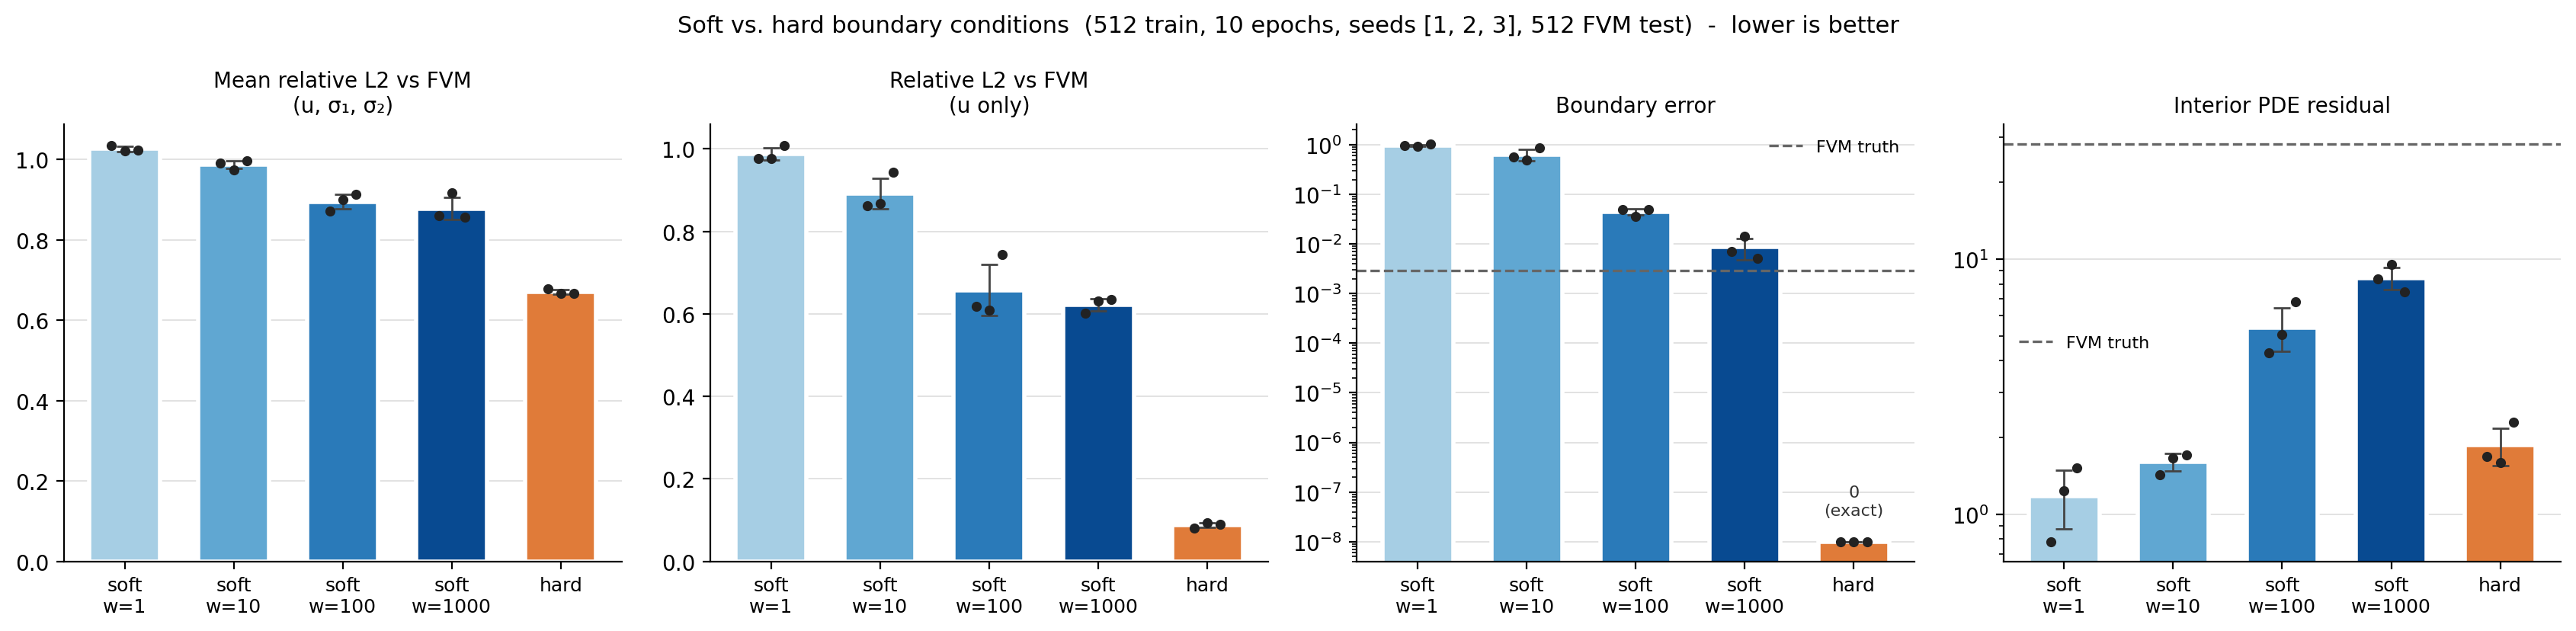

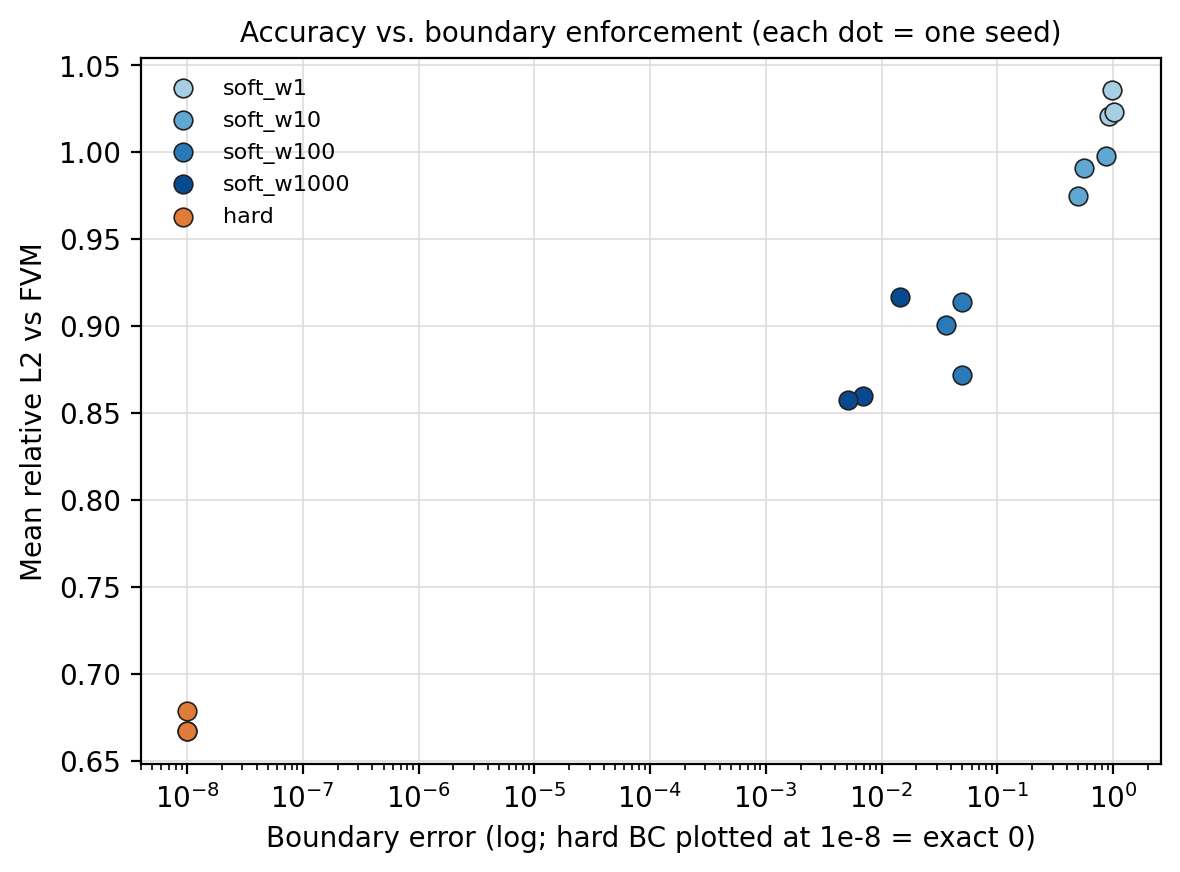

In [ ]:
# Comparison plot - one panel per metric, bars = mean over seeds, error bars = std, dots = individual seeds
import matplotlib.pyplot as plt
from IPython.display import display, Image   

names = list(results.keys())
soft_names = [n for n in names if n.startswith('soft')]
blues = plt.cm.Blues(np.linspace(0.35, 0.9, max(len(soft_names), 1)))   # soft: light -> dark as the weight grows
colors = [blues[soft_names.index(n)] if n in soft_names else '#E07B39' for n in names]   # hard: orange
labels = [n.replace('soft_w', 'soft\nw=') for n in names]

panels = [('relL2_mean', 'Mean relative L2 vs FVM\n(u, σ₁, σ₂)', False),
          ('relL2_u',    'Relative L2 vs FVM\n(u only)',         False),
          ('bc_error',   'Boundary error',                      True),
          ('pde_interior', 'Interior PDE residual',             True)]

fig, axes = plt.subplots(1, 4, figsize=(17, 4.2))
x = np.arange(len(names))
for ax, (key, title, log) in zip(axes, panels):
    vals = [np.array([r[key] for r in results[n]]) for n in names]
    means = np.array([v.mean() for v in vals]); stds = np.array([v.std() for v in vals])
    floor = 1e-8 if log else 0.0                                   # hard BC gives exactly 0 -> can't draw 0 on a log axis
    ax.bar(x, np.maximum(means, floor), width=0.65, color=colors, edgecolor='white', linewidth=2,
           yerr=stds, capsize=4, error_kw={'elinewidth': 1, 'ecolor': '#444'})
    for i, v in enumerate(vals):                                   # individual seeds
        ax.scatter(np.full(len(v), x[i]) + np.linspace(-0.12, 0.12, len(v)), np.maximum(v, floor),
                   s=14, color='#222', zorder=3)
        if log and means[i] == 0:
            ax.text(x[i], floor * 3, '0\n(exact)', ha='center', va='bottom', fontsize=8, color='#333')
    if key in ('bc_error', 'pde_interior'):                       # what the FVM solution itself scores
        ax.axhline(max(reference[key], floor), color='#666', ls='--', lw=1.2, label='FVM truth')
        ax.legend(loc='best', fontsize=8, frameon=False)
    if log:
        ax.set_yscale('log')
    ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=9)
    ax.set_title(title, fontsize=10)
    ax.grid(axis='y', color='#ddd', lw=0.6); ax.set_axisbelow(True)
    for s in ('top', 'right'):
        ax.spines[s].set_visible(False)

fig.suptitle(f'Soft vs. hard boundary conditions  ({NTRAIN} train, {EPOCHS} epochs, seeds {SEEDS}, {NTEST} FVM test)  -  lower is better',
             fontsize=11)
fig.tight_layout()
fig.savefig('bc_comparison.png', dpi=200, bbox_inches='tight')
plt.close(fig)
display(Image(filename='bc_comparison.png', width=1000))   # CHANGED: show the saved PNG inline

# Trade-off view: accuracy vs boundary error, one point per seed
fig, ax = plt.subplots(figsize=(6, 4.5))
for n, c in zip(names, colors):
    bc = np.maximum([r['bc_error'] for r in results[n]], 1e-8)
    ax.scatter(bc, [r['relL2_mean'] for r in results[n]], s=45, color=c, edgecolor='#222', lw=0.6, label=n)
ax.set_xscale('log')
ax.set_xlabel('Boundary error (log; hard BC plotted at 1e-8 = exact 0)')
ax.set_ylabel('Mean relative L2 vs FVM')
ax.set_title('Accuracy vs. boundary enforcement (each dot = one seed)', fontsize=10)
ax.grid(color='#ddd', lw=0.6); ax.set_axisbelow(True)
ax.legend(fontsize=8, frameon=False)
fig.tight_layout()
fig.savefig('bc_tradeoff.png', dpi=200, bbox_inches='tight')
plt.close(fig)
display(Image(filename='bc_tradeoff.png', width=600))   # CHANGED: show the saved PNG inline


In [ ]:
# ADDED: Models for the field plots soft BC vs Hard BC

import os

PLOT_MODELS = [('soft_w10', 'soft', 10), ('hard', 'hard', None)]
if 'trained' not in globals():
    trained = {}
for name, mode, w in PLOT_MODELS:
    path = f'plot_model_{name}.pth'
    if name in trained:
        continue                                          # already in memory
    if os.path.exists(path):
        print(f'loading {name} from {path}')
        trained[name] = build_model(mode)
        trained[name].load_state_dict(torch.load(path, map_location=exp_device))
    else:
        print(f'training {name} (seed 1) ...  (~5-10 min)')
        trained[name] = train_one(mode, w, seed=1, verbose=False)
        torch.save(trained[name].state_dict(), path)
    trained[name].eval()
print('ready:', list(trained))


training soft_w10 (seed 1) ...  (~5-10 min)
# params 740091, # conv layers 28
training hard (seed 1) ...  (~5-10 min)
# params 740091, # conv layers 28
ready: ['soft_w10', 'hard']


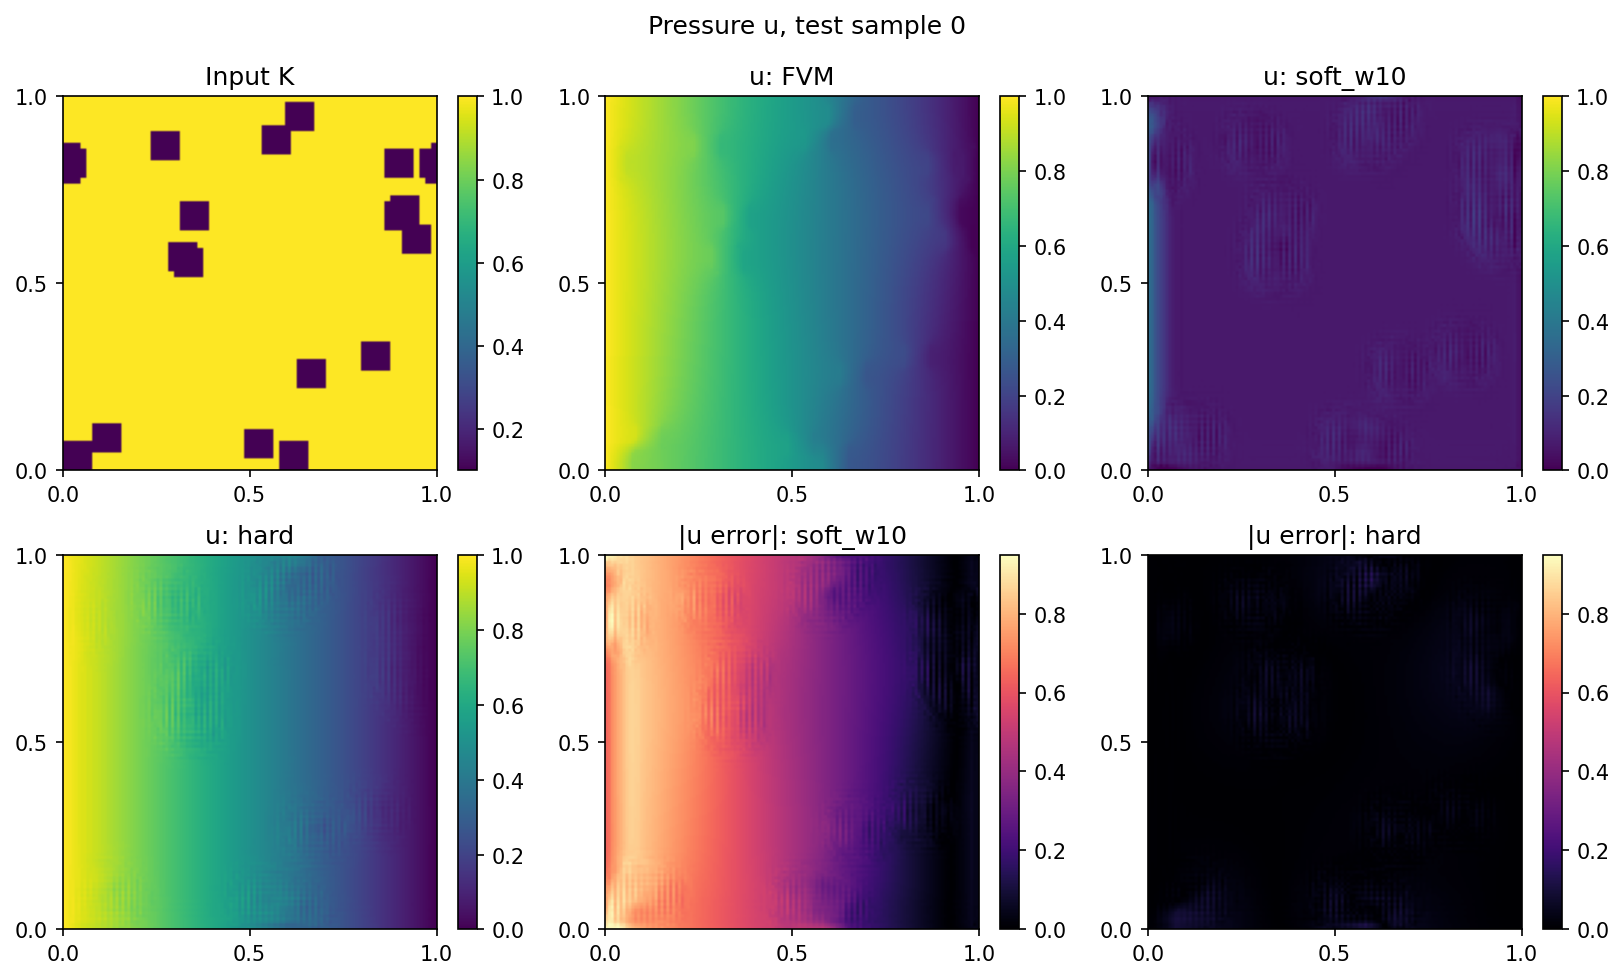

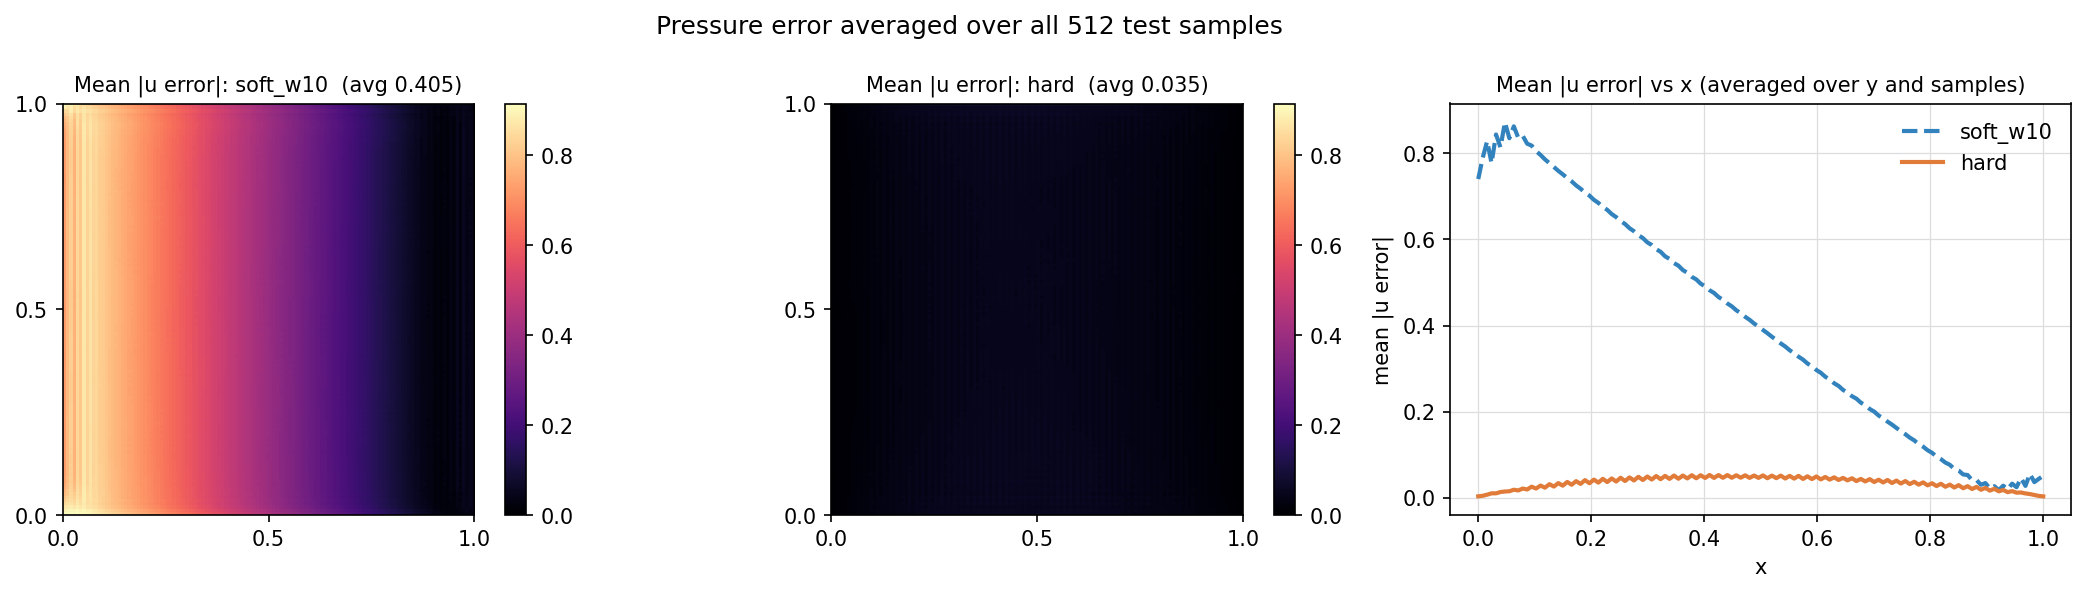

In [ ]:
# Compact pressure (u) figures - one test sample, and the error averaged over all test samples
import matplotlib.pyplot as plt
from IPython.display import display, Image

model_names = list(trained.keys())
ext = [0, 1, 0, 1]                                        # x left->right, y bottom->top

# Mean abs u error over every test sample 
err_sum = {n: torch.zeros(128, 128) for n in model_names}
with torch.no_grad():
    for input, target in test_loader_exp:
        for n in model_names:
            u_pred = trained[n](input.to(exp_device))[:, 0].cpu()
            err_sum[n] += (u_pred - target[:, 0]).abs().sum(0)
mean_err = {n: (err_sum[n] / len(x_test)).numpy() for n in model_names}

#  one sample, u only (2 x 3) 
IDX = 0                                                  
with torch.no_grad():
    u = {'FVM': y_test[IDX, 0].numpy()}
    for n in model_names:
        u[n] = trained[n](x_test[[IDX]].to(exp_device))[0, 0].cpu().numpy()
fig, axes = plt.subplots(2, 3, figsize=(11, 6.6))
im = axes[0, 0].imshow(x_test[IDX, 0].numpy(), origin='lower', extent=ext, cmap='viridis')
axes[0, 0].set_title('Input K'); fig.colorbar(im, ax=axes[0, 0], fraction=0.046)
for ax, n in zip([axes[0, 1], axes[0, 2], axes[1, 0]], ['FVM'] + model_names):
    im = ax.imshow(u[n], origin='lower', extent=ext, cmap='viridis', vmin=0, vmax=1)
    ax.set_title(f'u: {n}'); fig.colorbar(im, ax=ax, fraction=0.046)
vmax = max(np.abs(u[n] - u['FVM']).max() for n in model_names)
for ax, n in zip([axes[1, 1], axes[1, 2]], model_names):
    im = ax.imshow(np.abs(u[n] - u['FVM']), origin='lower', extent=ext, cmap='magma', vmin=0, vmax=vmax)
    ax.set_title(f'|u error|: {n}'); fig.colorbar(im, ax=ax, fraction=0.046)
for ax in axes.flat:
    ax.set_xticks([0, 0.5, 1]); ax.set_yticks([0, 0.5, 1])
fig.suptitle(f'Pressure u, test sample {IDX}', fontsize=12)
fig.tight_layout()
fig.savefig('u_sample_compact.png', dpi=150, bbox_inches='tight'); plt.close(fig)
display(Image(filename='u_sample_compact.png', width=800))

# mean abs u error over all test samples 
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
vmax = max(e.max() for e in mean_err.values())
for ax, n in zip(axes[:2], model_names):
    im = ax.imshow(mean_err[n], origin='lower', extent=ext, cmap='magma', vmin=0, vmax=vmax)
    ax.set_title(f'Mean |u error|: {n}  (avg {mean_err[n].mean():.3f})', fontsize=10)
    ax.set_xticks([0, 0.5, 1]); ax.set_yticks([0, 0.5, 1])
    fig.colorbar(im, ax=ax, fraction=0.046)
xs = np.linspace(0, 1, 128)
style = {'soft_w10': dict(color='#3182BD', ls='--'), 'hard': dict(color='#E07B39', ls='-')}
for n in model_names:
    axes[2].plot(xs, mean_err[n].mean(0), lw=2, label=n, **style.get(n, {}))   # average over y as well
axes[2].set_xlabel('x'); axes[2].set_ylabel('mean |u error|')
axes[2].set_title('Mean |u error| vs x (averaged over y and samples)', fontsize=10)
axes[2].grid(color='#ddd', lw=0.6); axes[2].legend(frameon=False)
fig.suptitle(f'Pressure error averaged over all {len(x_test)} test samples', fontsize=12)
fig.tight_layout()
fig.savefig('u_error_average.png', dpi=150, bbox_inches='tight'); plt.close(fig)
display(Image(filename='u_error_average.png', width=1100))
